In [4]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
# Load dataset (make sure the filename matches your local file)
df = pd.read_csv("bank_transactions.csv")

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
df.head()

Dataset Shape: 10000 rows, 20 columns



,transaction_id,transaction_amount,login_attempts,device_risk_score,transfer_frequency,anomaly_score,account_age_days,transaction_time_hour,failed_transactions_last_30d,avg_monthly_balance,daily_transaction_count,geo_distance_km,session_duration_minutes,transaction_velocity_score,payment_channel,authentication_type,card_present_flag,international_transaction_flag,suspicious_ip_flag,fraud_flag
0,1000001,17829.01,4,12.0,13,0.37,2354,22,25,112760.07,63,3189,92,71.8,POS Terminal,OTP,1,1,1,False
1,1000002,16401.83,1,34.3,17,0.26,3181,17,15,118899.52,83,839,63,11.8,Web Banking,Biometric,0,0,1,False
2,1000003,9678.29,8,67.8,39,0.15,1390,3,2,408168.98,9,3938,80,35.7,ATM,OTP,1,0,1,False
3,1000004,19013.38,5,17.8,42,0.55,3716,16,6,80771.69,78,11111,11,74.8,Mobile App,OTP,1,1,0,False
4,1000005,13834.95,3,88.9,63,0.24,4694,16,10,382265.32,17,3171,87,0.0,Mobile App,OTP,1,0,0,False


CONVERTING TARGET VARIABLE TO NUMERIC

In [6]:
# Convert boolean string labels to 1 and 0
df['fraud_flag'] = df['fraud_flag'].astype(str).str.upper().map({'TRUE': 1, 'FALSE': 0})

# Check target variable distribution
print("Target Variable (fraud_flag) Distribution:")
print(df['fraud_flag'].value_counts())
print("\nPercentage:")
print(df['fraud_flag'].value_counts(normalize=True) * 100)

Target Variable (fraud_flag) Distribution:
fraud_flag
0    8749
1    1251
Name: count, dtype: int64

Percentage:
fraud_flag
0    87.49
1    12.51
Name: proportion, dtype: float64


SEPARATE FEATURES AND TARGET

In [7]:
# Separate features and target label
X = df.drop(columns=['transaction_id', 'fraud_flag'])
y = df['fraud_flag']

print("Features shape (X):", X.shape)
print("Target shape (y):", y.shape)

Features shape (X): (10000, 18)
Target shape (y): (10000,)


CATEGORICAL AND NUMERIC TRANSFORMERS

In [8]:
# Categorical columns that need One-Hot Encoding
categorical_cols = ['payment_channel', 'authentication_type']

# Numerical columns that need Standard Scaling
numerical_cols = [col for col in X.columns if col not in categorical_cols]

# Build ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical_cols)
    ]
)

print("Numerical Columns:", numerical_cols)
print("Categorical Columns:", categorical_cols)

Numerical Columns: ['transaction_amount', 'login_attempts', 'device_risk_score', 'transfer_frequency', 'anomaly_score', 'account_age_days', 'transaction_time_hour', 'failed_transactions_last_30d', 'avg_monthly_balance', 'daily_transaction_count', 'geo_distance_km', 'session_duration_minutes', 'transaction_velocity_score', 'card_present_flag', 'international_transaction_flag', 'suspicious_ip_flag']
Categorical Columns: ['payment_channel', 'authentication_type']


FIT AND TRANSFORM FEATURE MATRIX

In [9]:
# Fit and transform features
X_processed = preprocessor.fit_transform(X)

print("✅ Preprocessing Complete!")
print(f"Original Feature Shape: {X.shape}")
print(f"Processed Feature Matrix Shape: {X_processed.shape}")

✅ Preprocessing Complete!
Original Feature Shape: (10000, 18)
Processed Feature Matrix Shape: (10000, 22)


Train-Test Split

In [10]:
# Cell 7: Train-Test Split
from sklearn.model_selection import train_test_split

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_processed, y, test_size=0.2, random_state=42, stratify=y
)

print(f"✅ Train-test split complete!")
print(f"Training set: {X_train.shape[0]} samples")
print(f"Testing set:  {X_test.shape[0]} samples")

✅ Train-test split complete!
Training set: 8000 samples
Testing set:  2000 samples


Handling Class Imbalance with SMOTE

In [11]:
# Cell 8: Handle Class Imbalance using SMOTE
from imblearn.over_sampling import SMOTE

# Initialize SMOTE
smote = SMOTE(random_state=42)

# Resample ONLY the training data
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print("=== BEFORE SMOTE ===")
print(pd.Series(y_train).value_counts())

print("\n=== AFTER SMOTE (Balanced Training Set) ===")
print(pd.Series(y_train_res).value_counts())

=== BEFORE SMOTE ===
fraud_flag
0    6999
1    1001
Name: count, dtype: int64

=== AFTER SMOTE (Balanced Training Set) ===
fraud_flag
0    6999
1    6999
Name: count, dtype: int64


Train Machine Learning Models

In [12]:
# Cell 9: Machine Learning Model Training
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Initialize models
lr_model = LogisticRegression(max_iter=1000, random_state=42)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# Fit models on SMOTE-balanced training data
print("Training Logistic Regression...")
lr_model.fit(X_train_res, y_train_res)

print("Training Random Forest...")
rf_model.fit(X_train_res, y_train_res)

print("✅ ML Models trained successfully!")

Training Logistic Regression...
Training Random Forest...
✅ ML Models trained successfully!


Evaluate & Compare ML Models

In [14]:
# Cell 10: Model Evaluation & Comparison Matrix
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Predictions
y_pred_lr = lr_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

# ROC-AUC Scores
auc_lr = roc_auc_score(y_test, lr_model.predict_proba(X_test)[:, 1])
auc_rf = roc_auc_score(y_test, rf_model.predict_proba(X_test)[:, 1])

print("=== LOGISTIC REGRESSION REPORT ===")
print(classification_report(y_test, y_pred_lr))
print(f"ROC-AUC Score: {auc_lr:.4f}\n")

print("=== RANDOM FOREST REPORT ===")
print(classification_report(y_test, y_pred_rf))
print(f"ROC-AUC Score: {auc_rf:.4f}\n")

=== LOGISTIC REGRESSION REPORT ===
              precision    recall  f1-score   support

           0       0.99      0.93      0.96      1750
           1       0.66      0.92      0.77       250

    accuracy                           0.93      2000
   macro avg       0.83      0.93      0.87      2000
weighted avg       0.95      0.93      0.94      2000

ROC-AUC Score: 0.9787

=== RANDOM FOREST REPORT ===
              precision    recall  f1-score   support

           0       0.98      0.96      0.97      1750
           1       0.76      0.87      0.81       250

    accuracy                           0.95      2000
   macro avg       0.87      0.92      0.89      2000
weighted avg       0.95      0.95      0.95      2000

ROC-AUC Score: 0.9736



Plot Confusion Matrices

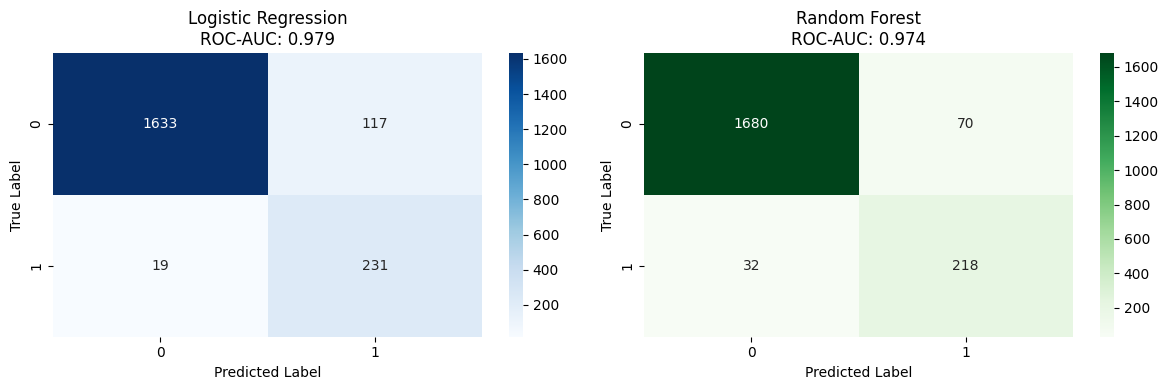

In [15]:
# Cell 11: Confusion Matrix Visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title(f'Logistic Regression\nROC-AUC: {auc_lr:.3f}')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title(f'Random Forest\nROC-AUC: {auc_rf:.3f}')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()

Build & Train TensorFlow Neural Network

In [16]:
# Cell 12: TensorFlow Neural Network Implementation
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# 1. Automatically pick SMOTE data if available, otherwise fallback to X_train
if 'X_train_res' in globals():
    X_train_dl, y_train_dl = X_train_res, y_train_res
    print("Using SMOTE-balanced training data...")
else:
    X_train_dl, y_train_dl = X_train, y_train
    print("Using original standard training data...")

# 2. Define input dimension based on feature count
input_dim = X_train_dl.shape[1]

# 3. Build Neural Network Architecture
dl_model = Sequential([
    Dense(64, activation='relu', input_shape=(input_dim,)),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')  # Binary classification output (0 or 1)
])

# 4. Compile Model
dl_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

# 5. Define Early Stopping (prevents overtraining)
early_stop = EarlyStopping(
    monitor='val_loss', 
    patience=5, 
    restore_best_weights=True
)

# 6. Train the TensorFlow Model
print("\nTraining TensorFlow Deep Learning Model...")
history = dl_model.fit(
    X_train_dl, y_train_dl,
    epochs=30,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

print("\n✅ Deep Learning Model trained successfully!")

Using SMOTE-balanced training data...

Training TensorFlow Deep Learning Model...
Epoch 1/30


C:\Users\USER\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8023 - auc: 0.8916 - loss: 0.4095 - val_accuracy: 0.9346 - val_auc: 0.0000e+00 - val_loss: 0.1987
Epoch 2/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9173 - auc: 0.9704 - loss: 0.2096 - val_accuracy: 0.9496 - val_auc: 0.0000e+00 - val_loss: 0.1665
Epoch 3/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9284 - auc: 0.9760 - loss: 0.1857 - val_accuracy: 0.9571 - val_auc: 0.0000e+00 - val_loss: 0.1613
Epoch 4/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9330 - auc: 0.9777 - loss: 0.1762 - val_accuracy: 0.9500 - val_auc: 0.0000e+00 - val_loss: 0.1824
Epoch 5/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9351 - auc: 0.9791 - loss: 0.1697 - val_accuracy: 0.9661 - val_auc: 0.0000e+00 - val_loss: 0.1457
Epoch 6/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9390 - auc: 0.9804 - loss: 0.1642 - val_accuracy: 0.9579 - val_auc: 0.0000e+00 - val_loss: 0.1551
Epoch 7/30
175/175 ━━━━━━━━

Evaluate TensorFlow Model & Compare All 3 Models

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
=== TENSORFLOW DEEP LEARNING MODEL REPORT ===
              precision    recall  f1-score   support

           0       0.98      0.96      0.97      1750
           1       0.74      0.87      0.80       250

    accuracy                           0.94      2000
   macro avg       0.86      0.91      0.88      2000
weighted avg       0.95      0.94      0.95      2000

ROC-AUC Score: 0.9757

=== FINAL MODULE IV MODEL COMPARISON ===
              Model  ROC-AUC Score
Logistic Regression       0.978704
      Random Forest       0.973621
     TensorFlow DNN       0.975682


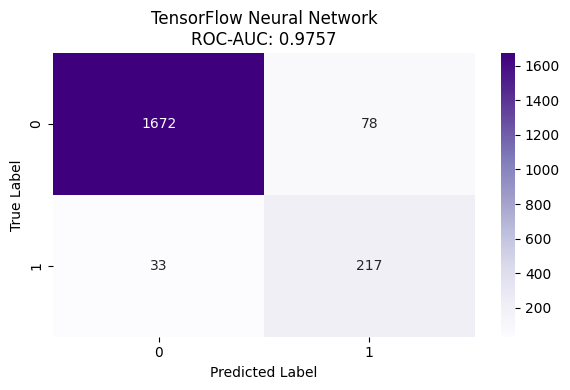

In [17]:
# Cell 13: Deep Learning Evaluation & Final Model Comparison
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Get raw probability predictions for the TensorFlow model
y_pred_proba_dl = dl_model.predict(X_test).ravel()

# 2. Convert probabilities to binary predictions (threshold = 0.5)
y_pred_dl = (y_pred_proba_dl > 0.5).astype(int)

# 3. Calculate TensorFlow ROC-AUC Score
auc_dl = roc_auc_score(y_test, y_pred_proba_dl)

print("=== TENSORFLOW DEEP LEARNING MODEL REPORT ===")
print(classification_report(y_test, y_pred_dl))
print(f"ROC-AUC Score: {auc_dl:.4f}\n")

# 4. Summary Table Comparing All Models
comparison_df = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'TensorFlow DNN'],
    'ROC-AUC Score': [auc_lr, auc_rf, auc_dl]
})

print("=== FINAL MODULE IV MODEL COMPARISON ===")
print(comparison_df.to_string(index=False))

# 5. Plot Confusion Matrix for TensorFlow Model
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_dl), annot=True, fmt='d', cmap='Purples')
plt.title(f'TensorFlow Neural Network\nROC-AUC: {auc_dl:.4f}')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

Constructing the Account Graph & Search Algorithms

In [18]:
# Cell 14: Search Algorithms Implementation (Module II)
import heapq
import time

# 1. Build a Fraud Account Network (Graph Representation)
# Adjacency list: node -> [(neighbor, risk_weight/cost)]
account_graph = {
    'ACC_START': [('ACC_A', 10), ('ACC_B', 25)],
    'ACC_A': [('ACC_C', 15), ('ACC_D', 30)],
    'ACC_B': [('ACC_D', 10), ('ACC_E', 40)],
    'ACC_C': [('ACC_TARGET', 20)],
    'ACC_D': [('ACC_TARGET', 15)],
    'ACC_E': [('ACC_TARGET', 5)],
    'ACC_TARGET': []
}

# Heuristic values (estimated risk distance to fraud target account)
heuristic = {
    'ACC_START': 30,
    'ACC_A': 20,
    'ACC_B': 20,
    'ACC_C': 15,
    'ACC_D': 10,
    'ACC_E': 5,
    'ACC_TARGET': 0
}

# --- 1. BFS ---
def bfs(graph, start, goal):
    queue = [[start]]
    visited = set()
    while queue:
        path = queue.pop(0)
        node = path[-1]
        if node == goal:
            return path
        if node not in visited:
            visited.add(node)
            for neighbor, _ in graph.get(node, []):
                queue.append(list(path) + [neighbor])
    return None

# --- 2. DFS ---
def dfs(graph, start, goal):
    stack = [[start]]
    visited = set()
    while stack:
        path = stack.pop()
        node = path[-1]
        if node == goal:
            return path
        if node not in visited:
            visited.add(node)
            for neighbor, _ in graph.get(node, []):
                stack.append(list(path) + [neighbor])
    return None

# --- 3. Best-First Search ---
def best_first_search(graph, start, goal, h):
    pq = [(h[start], [start])]
    visited = set()
    while pq:
        _, path = heapq.heappop(pq)
        node = path[-1]
        if node == goal:
            return path
        if node not in visited:
            visited.add(node)
            for neighbor, _ in graph.get(node, []):
                heapq.heappush(pq, (h[neighbor], list(path) + [neighbor]))
    return None

# --- 4. A* Search ---
def a_star_search(graph, start, goal, h):
    # (f_score, g_score, path)
    pq = [(h[start], 0, [start])]
    visited = {}
    while pq:
        f, g, path = heapq.heappop(pq)
        node = path[-1]
        if node == goal:
            return path, g
        if node not in visited or g < visited[node]:
            visited[node] = g
            for neighbor, cost in graph.get(node, []):
                new_g = g + cost
                new_f = new_g + h[neighbor]
                heapq.heappush(pq, (new_f, new_g, list(path) + [neighbor]))
    return None, float('inf')

print("✅ Search algorithms implemented successfully!")

✅ Search algorithms implemented successfully!


Run & Compare Search Performance

In [19]:
# Cell 15: Benchmark and Compare Search Algorithms
start_node = 'ACC_START'
target_node = 'ACC_TARGET'

# Execute BFS
t0 = time.perf_counter()
bfs_path = bfs(account_graph, start_node, target_node)
bfs_time = (time.perf_counter() - t0) * 1000

# Execute DFS
t0 = time.perf_counter()
dfs_path = dfs(account_graph, start_node, target_node)
dfs_time = (time.perf_counter() - t0) * 1000

# Execute Best-First
t0 = time.perf_counter()
best_path = best_first_search(account_graph, start_node, target_node, heuristic)
best_time = (time.perf_counter() - t0) * 1000

# Execute A*
t0 = time.perf_counter()
astar_path, astar_cost = a_star_search(account_graph, start_node, target_node, heuristic)
astar_time = (time.perf_counter() - t0) * 1000

# Results Comparison Table
search_results = pd.DataFrame({
    'Algorithm': ['BFS', 'DFS', 'Best-First Search', 'A* Search'],
    'Discovered Path': [str(bfs_path), str(dfs_path), str(best_path), str(astar_path)],
    'Execution Time (ms)': [bfs_time, dfs_time, best_time, astar_time]
})

print("=== MODULE II: SEARCH ALGORITHMS COMPARISON ===")
print(search_results.to_string(index=False))

=== MODULE II: SEARCH ALGORITHMS COMPARISON ===
        Algorithm                               Discovered Path  Execution Time (ms)
              BFS ['ACC_START', 'ACC_A', 'ACC_C', 'ACC_TARGET']               0.1264
              DFS ['ACC_START', 'ACC_B', 'ACC_E', 'ACC_TARGET']               0.0972
Best-First Search ['ACC_START', 'ACC_A', 'ACC_D', 'ACC_TARGET']               0.1030
        A* Search ['ACC_START', 'ACC_A', 'ACC_C', 'ACC_TARGET']               0.1141


STARTING Rule-Based Systems & Probabilistic Reasoning 

Forward Chaining Rule-Based Expert System

In [20]:
# Cell 16: Rule-Based Expert System (Module III)

class FraudInferenceEngine:
    def __init__(self):
        # Knowledge Base Rules
        self.rules = [
            {
                'name': 'Rule 1: High Geo-Distance & Suspicious IP',
                'condition': lambda row: row['geo_distance_km'] > 5000 and row['suspicious_ip_flag'] == 1,
                'risk_flag': 'CRITICAL_GEO_IP_RISK',
                'score_addition': 40
            },
            {
                'name': 'Rule 2: High Amount & Foreign/Card Not Present',
                'condition': lambda row: row['transaction_amount'] > 15000 and row['card_present_flag'] == 0,
                'risk_flag': 'HIGH_AMOUNT_REMOTE_RISK',
                'score_addition': 35
            },
            {
                'name': 'Rule 3: Excessive Failed Login Attempts',
                'condition': lambda row: row['login_attempts'] >= 5,
                'risk_flag': 'EXCESSIVE_LOGIN_FAILURES',
                'score_addition': 25
            }
        ]

    def evaluate_transaction(self, transaction_row):
        triggered_rules = []
        total_risk_score = 0

        # Forward Chaining Evaluation
        for rule in self.rules:
            if rule['condition'](transaction_row):
                triggered_rules.append(rule['name'])
                total_risk_score += rule['score_addition']

        decision = "FLAGGED_FOR_REVIEW" if total_risk_score >= 50 else "APPROVED"
        
        return {
            'triggered_rules': triggered_rules,
            'rule_risk_score': min(total_risk_score, 100),
            'expert_decision': decision
        }

# Instantiate Engine
expert_system = FraudInferenceEngine()

# Test on a high-risk sample from original dataframe
sample_tx = df.iloc[0]  # First transaction in original CSV
expert_output = expert_system.evaluate_transaction(sample_tx)

print("=== MODULE III: EXPERT SYSTEM EVALUATION SAMPLE ===")
print("Transaction ID:", sample_tx['transaction_id'])
print("Triggered Rules:", expert_output['triggered_rules'])
print("Calculated Risk Score:", expert_output['rule_risk_score'])
print("Expert System Decision:", expert_output['expert_decision'])

=== MODULE III: EXPERT SYSTEM EVALUATION SAMPLE ===
Transaction ID: 1000001
Triggered Rules: []
Calculated Risk Score: 0
Expert System Decision: APPROVED


Probabilistic Reasoning using Naive Bayesian Network Logic

In [21]:
# Cell 17: Bayesian Probabilistic Reasoning Model
import numpy as np

class SimpleBayesianNetwork:
    def __init__(self):
        self.p_fraud = None
        self.p_suspicious_ip_given_fraud = None
        self.p_suspicious_ip_given_legit = None

    def fit(self, df_data):
        total = len(df_data)
        frauds = df_data[df_data['fraud_flag'] == 1]
        legits = df_data[df_data['fraud_flag'] == 0]

        # Prior Probabilities
        self.p_fraud = len(frauds) / total
        p_legit = 1 - self.p_fraud

        # Likelihoods for Suspicious IP Flag
        self.p_suspicious_ip_given_fraud = (frauds['suspicious_ip_flag'] == 1).mean()
        self.p_suspicious_ip_given_legit = (legits['suspicious_ip_flag'] == 1).mean()

        print(f"Prior P(Fraud): {self.p_fraud:.4f}")
        print(f"Likelihood P(Suspicious_IP | Fraud): {self.p_suspicious_ip_given_fraud:.4f}")
        print(f"Likelihood P(Suspicious_IP | Legit): {self.p_suspicious_ip_given_legit:.4f}")

    def predict_posterior_fraud(self, has_suspicious_ip):
        # Bayes Theorem: P(Fraud | Evidence) = P(Evidence | Fraud) * P(Fraud) / P(Evidence)
        if has_suspicious_ip == 1:
            p_evidence_given_fraud = self.p_suspicious_ip_given_fraud
            p_evidence_given_legit = self.p_suspicious_ip_given_legit
        else:
            p_evidence_given_fraud = 1 - self.p_suspicious_ip_given_fraud
            p_evidence_given_legit = 1 - self.p_suspicious_ip_given_legit

        p_evidence = (p_evidence_given_fraud * self.p_fraud) + (p_evidence_given_legit * (1 - self.p_fraud))
        
        posterior_p_fraud = (p_evidence_given_fraud * self.p_fraud) / p_evidence
        return posterior_p_fraud

# Fit Bayesian Model
bayesian_net = SimpleBayesianNetwork()
bayesian_net.fit(df)

# Test Posterior Probability given Suspicious IP = 1
post_prob = bayesian_net.predict_posterior_fraud(has_suspicious_ip=1)
print(f"\n Posterior Probability P(Fraud | Suspicious_IP=1): {post_prob * 100:.2f}%")

Prior P(Fraud): 0.1251
Likelihood P(Suspicious_IP | Fraud): 0.5132
Likelihood P(Suspicious_IP | Legit): 0.4987

 Posterior Probability P(Fraud | Suspicious_IP=1): 12.83%


Time Series Fraud Trend Aggregation & Forecasting

=== MODULE V: TIME SERIES SUMMARY (First 5 Hours) ===
   transaction_time_hour  fraud_transactions  3h_Moving_Avg  \
0                      0                  55      55.000000   
1                      1                  47      51.000000   
2                      2                  57      53.000000   
3                      3                  53      52.333333   
4                      4                  56      55.333333   

   Exp_Smoothing_Forecast  
0                 55.0000  
1                 52.6000  
2                 53.9200  
3                 53.6440  
4                 54.3508  


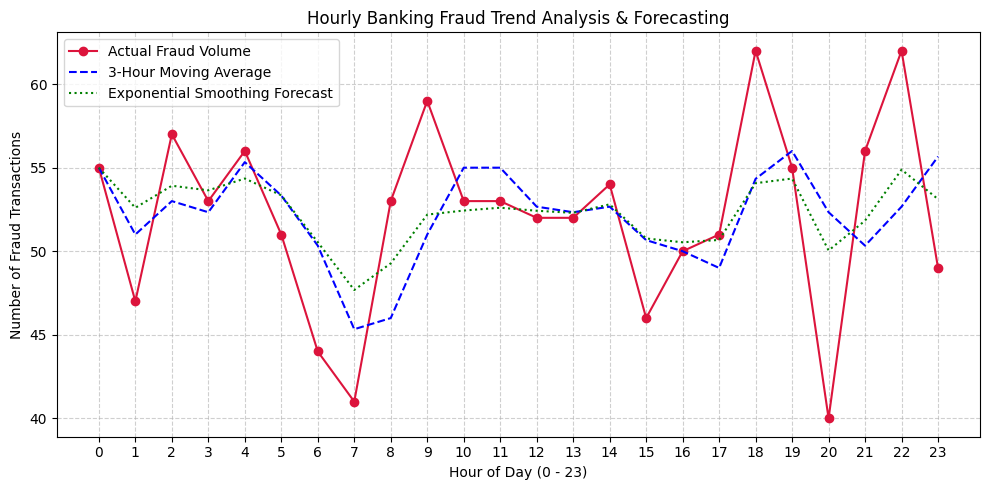

In [22]:
# Cell 18: Time Series Analysis & Fraud Forecasting (Module V)
import matplotlib.pyplot as plt

# 1. Aggregate total transactions and fraud counts by transaction_time_hour
time_series_df = df.groupby('transaction_time_hour').agg(
    total_transactions=('fraud_flag', 'count'),
    fraud_transactions=('fraud_flag', 'sum')
).reset_index()

# Calculate hourly fraud rate percentage
time_series_df['fraud_rate_%'] = (
    time_series_df['fraud_transactions'] / time_series_df['total_transactions']
) * 100

# 2. Simple Moving Average (SMA) and Exponential Smoothing Forecast
time_series_df['3h_Moving_Avg'] = time_series_df['fraud_transactions'].rolling(window=3, min_periods=1).mean()
time_series_df['Exp_Smoothing_Forecast'] = time_series_df['fraud_transactions'].ewm(alpha=0.3, adjust=False).mean()

print("=== MODULE V: TIME SERIES SUMMARY (First 5 Hours) ===")
print(time_series_df[['transaction_time_hour', 'fraud_transactions', '3h_Moving_Avg', 'Exp_Smoothing_Forecast']].head())

# 3. Plot Time Series Trends & Forecast
plt.figure(figsize=(10, 5))
plt.plot(time_series_df['transaction_time_hour'], time_series_df['fraud_transactions'], marker='o', label='Actual Fraud Volume', color='crimson')
plt.plot(time_series_df['transaction_time_hour'], time_series_df['3h_Moving_Avg'], linestyle='--', label='3-Hour Moving Average', color='blue')
plt.plot(time_series_df['transaction_time_hour'], time_series_df['Exp_Smoothing_Forecast'], linestyle=':', label='Exponential Smoothing Forecast', color='green')

plt.title('Hourly Banking Fraud Trend Analysis & Forecasting')
plt.xlabel('Hour of Day (0 - 23)')
plt.ylabel('Number of Fraud Transactions')
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

SAVING THE MODELS

In [27]:
import os
import joblib

# 1. Create 'MODELS' folder if it doesn't already exist
os.makedirs('MODELS', exist_ok=True)

# 2. Implicitly dump models directly into the 'MODELS' directory
joblib.dump(preprocessor, 'MODELS/preprocessor.joblib')
joblib.dump(lr_model, 'MODELS/logistic_regression_model.joblib')
joblib.dump(rf_model, 'MODELS/random_forest_model.joblib')

# 3. TensorFlow also supports direct path saving
dl_model.save('MODELS/tensorflow_fraud_model.keras')

print("All models implicitly saved directly inside the 'MODELS/' folder!")

All models implicitly saved directly inside the 'MODELS/' folder!
